<a href="https://colab.research.google.com/github/findsamirks-commits/Retail-ML-vs-DL-Architectures/blob/main/notebooks/Spice-Catalog-Vision-DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Automated Catalog Vision: Deep Learning Track
Unlike Machine Learning which requires manual feature engineering on tabular data, Deep Learning uses neural networks to automatically extract features from raw, unstructured data—like the pixels in a product image.

In this notebook, we build a Convolutional Neural Network (CNN) using PyTorch to visually classify whether a vendor's uploaded spice image is valid or defective.

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np

# 1. Generate Synthetic Unstructured Data (Raw Pixels)
# Simulating 100 images: 3 color channels (RGB), 64x64 pixels
# Unlike ML (Rows x Columns), DL handles Tensors (Batch x Channels x Height x Width)
num_images = 100
X_images = torch.rand(num_images, 3, 64, 64)

# Binary labels: 0 = Valid Spice Packet, 1 = Defective/Blurry
y_labels = torch.randint(0, 2, (num_images,))

print(f"Deep Learning Data Shape: {X_images.shape}")
print("Notice there are no engineered features here—just raw pixel values!\n")

# 2. Define the Convolutional Neural Network (CNN)
class SpiceVisionCNN(nn.Module):
    def __init__(self):
        super(SpiceVisionCNN, self).__init__()
        # Convolutional layers act as automatic feature extractors (edges, textures, shapes)
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)

        # Fully connected layers to make the final classification
        self.fc1 = nn.Linear(32 * 16 * 16, 128)
        self.fc2 = nn.Linear(128, 2) # 2 output classes: Valid or Defective

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = x.view(x.size(0), -1) # Flatten the 3D tensor into a 1D vector
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Initialize the model and move it to the GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SpiceVisionCNN().to(device)
print(f"Model loaded on: {device}")
print(model)

Deep Learning Data Shape: torch.Size([100, 3, 64, 64])
Notice there are no engineered features here—just raw pixel values!

Model loaded on: cuda
SpiceVisionCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=8192, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
)


In [ ]:
import torch.optim as optim

# 3. Define the Loss Function and Optimizer
# CrossEntropyLoss handles the error measurement for classification
criterion = nn.CrossEntropyLoss()

# Adam optimizer updates the model weights based on the loss gradients
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 4. The Deep Learning Training Loop
epochs = 5
print(f"🚀 Starting Deep Learning Training on: {device}\n")

model.train() # Set the model to training mode

for epoch in range(epochs):
    # Move tensors to the designated device (GPU or CPU)
    inputs = X_images.to(device)
    labels = y_labels.to(device)

    # 4a. Zero the parameter gradients so they don't accumulate
    optimizer.zero_grad()

    # 4b. Forward Pass: Pass the images through the CNN
    outputs = model(inputs)

    # 4c. Calculate Loss: Compare the model's guess against the true labels
    loss = criterion(outputs, labels)

    # 4d. Backward Pass: Calculate the gradients
    loss.backward()

    # 4e. Optimize: Update the neural network weights
    optimizer.step()

    print(f"Epoch {epoch+1}/{epochs} | Loss: {loss.item():.4f}")

print("\n✅ Training Complete! The network is learning the visual features automatically.")

🚀 Starting Deep Learning Training on: cuda

Epoch 1/5 | Loss: 0.7099
Epoch 2/5 | Loss: 1.1390
Epoch 3/5 | Loss: 0.7068
Epoch 4/5 | Loss: 0.7371
Epoch 5/5 | Loss: 0.7574

✅ Training Complete! The network is learning the visual features automatically.


## Deep Learning Inference: Automatic Feature Representation

Unlike the XGBoost model where we manually created `Days_of_Cover` and encoded categories, the CNN passed raw 64x64 RGB pixel tensors through convolutional kernels (`nn.Conv2d`) and activation functions (`nn.ReLU`). The spatial filters learned edge, texture, and shape representations autonomously during backpropagation (`loss.backward()`).

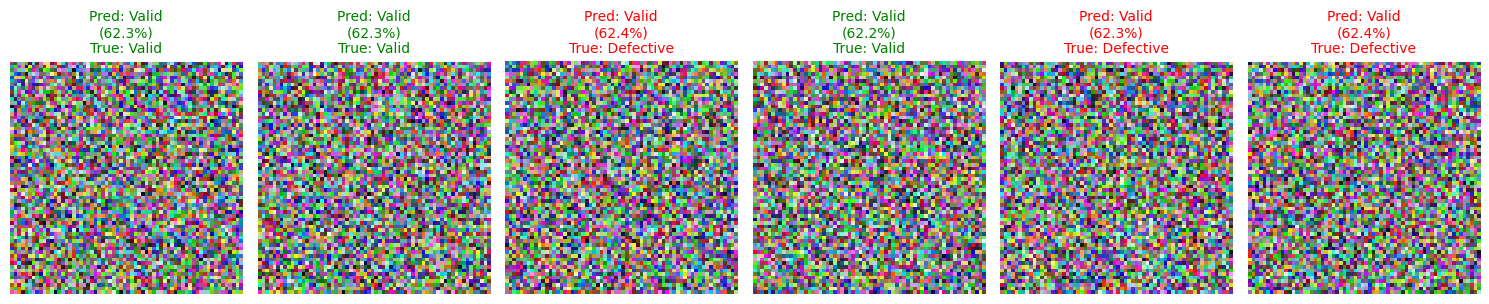

In [ ]:
# 5. Evaluate Predictions on Sample Images
model.eval()  # Set model to evaluation mode

with torch.no_grad():
    sample_inputs = X_images[:6].to(device)
    raw_outputs = model(sample_inputs)
    probabilities = torch.softmax(raw_outputs, dim=1)
    predicted_classes = torch.argmax(probabilities, dim=1)

# Visual check of 6 sample images and their classifications
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
classes = {0: "Valid", 1: "Defective"}

for i in range(6):
    img = X_images[i].permute(1, 2, 0).cpu().numpy()  # Convert (C, H, W) to (H, W, C) for Matplotlib
    pred = predicted_classes[i].item()
    true_label = y_labels[i].item()
    confidence = probabilities[i][pred].item() * 100

    axes[i].imshow(img)
    axes[i].axis('off')
    axes[i].set_title(f"Pred: {classes[pred]}\n({confidence:.1f}%)\nTrue: {classes[true_label]}",
                      color="green" if pred == true_label else "red", fontsize=10)

plt.tight_layout()
plt.show()

conv1 weights tensor shape: torch.Size([16, 3, 3, 3])


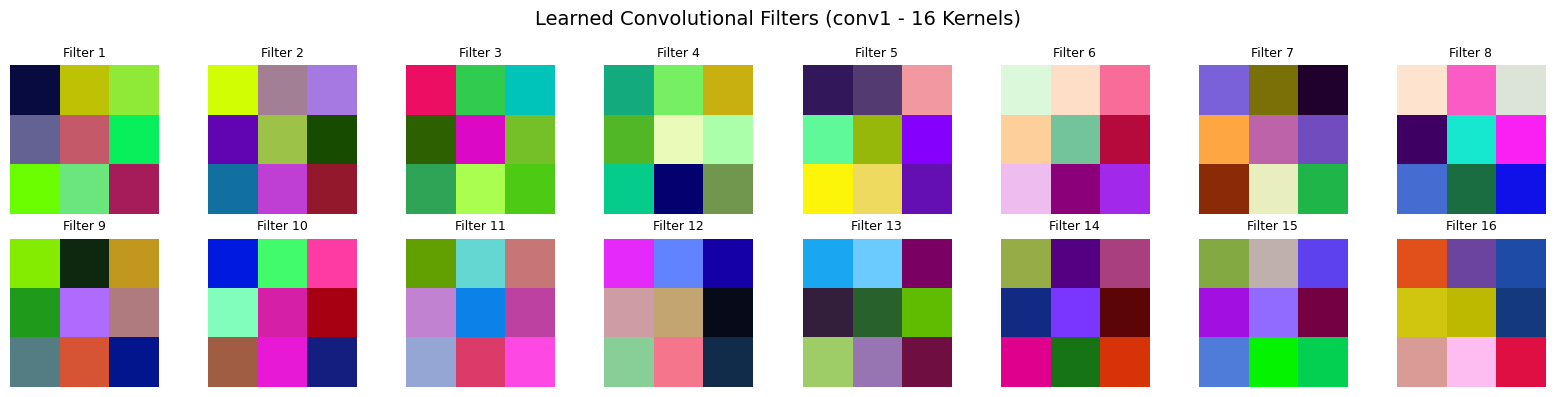

In [ ]:
# Extract the weights of the first convolutional layer (conv1)
# Shape: [out_channels, in_channels, height, width] -> [16, 3, 3, 3]
conv1_weights = model.conv1.weight.data.cpu()

print(f"conv1 weights tensor shape: {conv1_weights.shape}")

# Plot all 16 learned 3x3 filters
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
fig.suptitle("Learned Convolutional Filters (conv1 - 16 Kernels)", fontsize=14)

for i, ax in enumerate(axes.flat):
    # Normalize kernel values between 0 and 1 for RGB visualization
    kernel = conv1_weights[i]
    kernel_min, kernel_max = kernel.min(), kernel.max()
    kernel_normalized = (kernel - kernel_min) / (kernel_max - kernel_min + 1e-5)

    # Convert from [Channels, Height, Width] to [Height, Width, Channels]
    kernel_img = kernel_normalized.permute(1, 2, 0).numpy()

    ax.imshow(kernel_img, interpolation='nearest')
    ax.set_title(f"Filter {i+1}", fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.show()

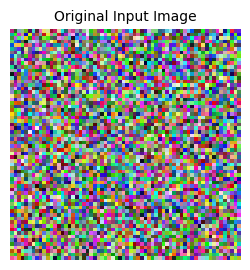

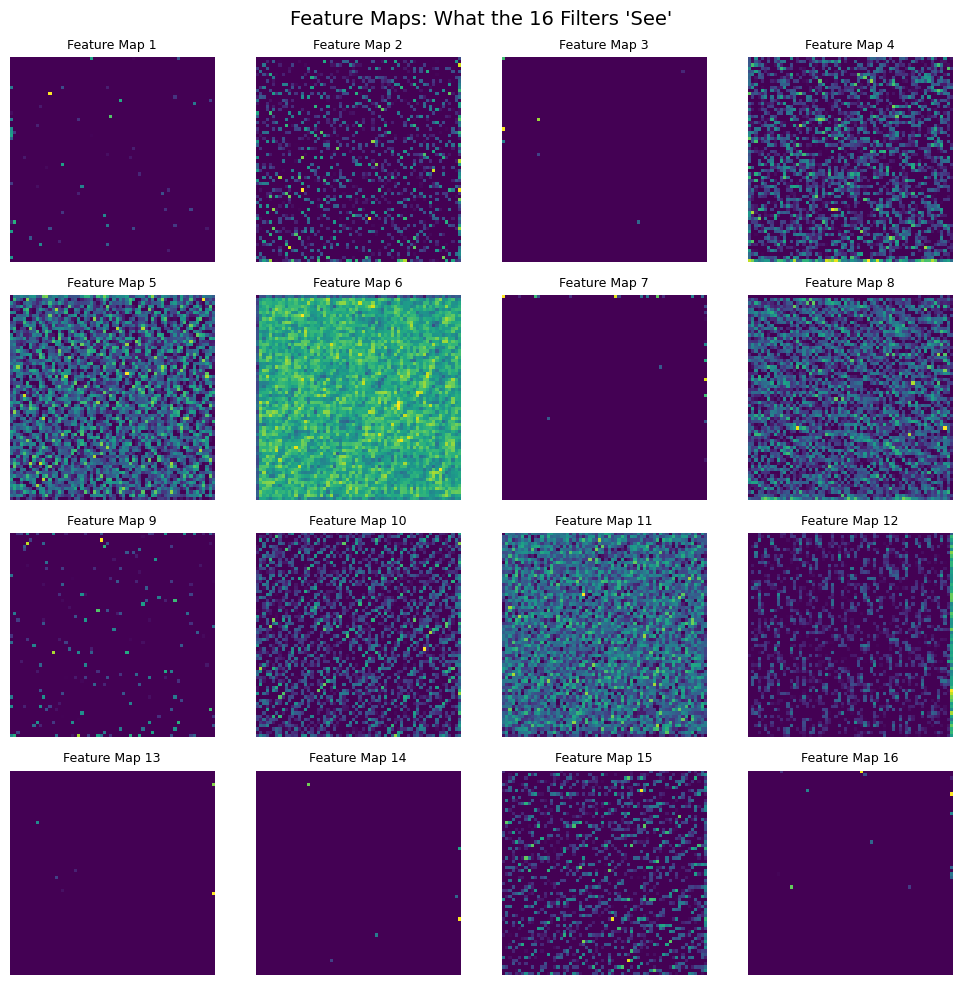

In [ ]:
# 6. Visualize the Feature Maps (Activations)
# Grab the very first image in our dataset
sample_img = X_images[0:1].to(device) # Shape: [1, 3, 64, 64]

model.eval()
with torch.no_grad():
    # Pass the image through the first layer and the ReLU activation
    conv1_out = model.conv1(sample_img)
    act1_out = model.relu(conv1_out)

# Drop the batch dimension and move to CPU for plotting
feature_maps = act1_out.squeeze(0).cpu().numpy() # Shape: [16, 64, 64]

# Plot the original input image
plt.figure(figsize=(3, 3))
plt.imshow(sample_img.squeeze(0).permute(1, 2, 0).cpu().numpy())
plt.title("Original Input Image", fontsize=10)
plt.axis('off')
plt.show()

# Plot the 16 feature maps generated by the convolutional layer
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
fig.suptitle("Feature Maps: What the 16 Filters 'See'", fontsize=14)

for i, ax in enumerate(axes.flat):
    # Feature maps are single-channel (intensity), so we use a colormap to visualize the activation strength
    ax.imshow(feature_maps[i], cmap='viridis')
    ax.set_title(f"Feature Map {i+1}", fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.show()

| Dimension | Traditional Machine Learning (XGBoost) | Deep Learning (PyTorch CNN) |
| :--- | :--- | :--- |
| **Data Modality** | Structured, tabular rows & columns (CSVs, SQL tables) | Unstructured high-dimensional tensors (images, audio, text) |
| **Input Shape** | 2D Matrix: `(n_samples, n_features)` | 4D Tensor: `(Batch, Channels, Height, Width)` |
| **Feature Extraction** | Manual engineering required (e.g., `Days_of_Cover`) | Automatic feature representation via learned convolutional filters |
| **Hardware Requirement** | CPU-efficient, lightweight execution | GPU-accelerated tensor math (NVIDIA T4 / CUDA cores) |
| **Optimization Target** | Tree splits minimizing objective loss (e.g., logloss) | Gradient descent updating weights via backpropagation (`loss.backward()`) |
| **Model Interpretability** | Transparent feature importance rankings | Black-box latent feature maps and filter weights |
| **Best Retail Use Case** | Inventory replenishment, markdown classification, churn | Visual catalog QA, defect detection, packaging validation |